# Human and Mammalian Brain Atlas (HMBA) - Marmoset Subcortex Xenium Spatial Transcriptomics: Slab coordinates and annotation

The Marmoset Subcortical Cell Atlas (MSCA), is a multiomic atlas of the common marmoset (Callithrix jacchus) subcortex that integrates single nucleus transcriptomics, chromatin accessibility, and spatial transcriptomics. Part of the Human and Mammalian Brain Atlas ([HMBA](https://brain-map.org/consortia/hmba)) effort within the NIH's BRAIN Initiative&reg; Cell Atlas Network ([BICAN](https://brain-bican.org/)), this dataset comprehensively samples key subcortical structures in the non-human primate, including the hippocampal formation, amygdala, olfactory areas, basal forebrain, thalamus, hypothalamus, midbrain, and major hindbrain structures (excluding cerebellar cortex). 

This cellular-resolution Xenium spatial transcriptomic dataset includes 5.6 million cells profiled from 47 coronal hemisections from a single adult male marmoset donor, sampling the rostral-caudal extent of subcortical structures. The spatial cells were mapped to the 1,737 snRNA-seq Clusters defined in the MSCA reference cell type taxonomy, and the resulting spatial localization of the Clusters provided anatomical anchoring and nomenclature to the Group and Class hierarchy levels of the MSCA taxonomy.

For more information on this dataset and the associated 10X Multiome data, please refer to the publication: [Dan, Turner, DeBerardine, et al. (2026). Spatial and regulatory organization of cell identity across the primate subcortex. Cell. https://doi.org/10.1016/j.cell.2026.10.007](https://doi.org/10.1016/j.cell.2026.10.007).

-----

In this notebook, we walk through the data available in this release and show how they are joined together to enable analyses at the cell level.

You need to be connected to the internet to run this notebook and have run through the [getting started notebook](https://alleninstitute.github.io/abc_atlas_access/notebooks/getting_started.html).

In [1]:
import json
import geojson
from typing import List, Tuple, Optional

import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from abc_atlas_access.abc_atlas_cache.abc_project_cache import AbcProjectCache


We will interact with the data using the **AbcProjectCache**. This cache object tracks which data has been downloaded and serves the path to the requested data on disk. For metadata, the cache can also directly serve up a Pandas DataFrame. See the [``getting_started``](https://alleninstitute.github.io/abc_atlas_access/notebooks/getting_started.html) notebook for more details on using the cache including installing it if it has not already been.

**Change the download_base variable to where you would like to download the data in your system.**

In [ ]:
download_base = Path('../../data/abc_atlas')
abc_cache = AbcProjectCache.from_cache_dir(
    cache_dir=download_base,
)

abc_cache.current_manifest

/Users/chris.morrison/src/abc_atlas_access/src/abc_atlas_access/abc_atlas_cache/cloud_cache.py:665: UserWarning: The manifest version recorded as last used for this cache -- releases/20261130/manifest.json-- is not a valid manifest for this dataset. Loading latest version -- releases/20261101/manifest.json -- instead.
  warnings.warn(msg, UserWarning)
/Users/chris.morrison/src/abc_atlas_access/src/abc_atlas_access/abc_atlas_cache/cloud_cache.py:697: OutdatedManifestWarning: You are loading
releases/20261101/manifest.json
which is newer than the most recent manifest file you have previously been working with
releases/20261130/manifest.json
It is possible that some data files have changed between these two data releases, which will force you to re-download those data files (currently downloaded files will not be overwritten). To continue using releases/20261130/manifest.json, run
type.load_manifest('releases/20261130/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


'releases/20261130/manifest.json'

## Data Overview

Below we list the available metadata and expression matrix files available. The data are split across a set of metadata tables and h5ad files. The three h5ad files contain the raw counts, batch-normalized counts, and a natural log transformation of the batch-normalized counts.

In [3]:
for dataset_name in ['HMBA-Subcortex-Xenium-Marmoset']:
    print(f"Dataset: {dataset_name}")
    metadata_files = abc_cache.list_metadata_files(dataset_name)
    print(f"Metadata files: {metadata_files}")
    expression_matrix_files = abc_cache.list_expression_matrix_files(dataset_name)
    print(f"Expression matrix files: {expression_matrix_files}\n")

Dataset: HMBA-Subcortex-Xenium-Marmoset
Metadata files: ['additional_cell_metadata', 'ccf_coordinates', 'cell_anatomical_annotations', 'cell_metadata', 'cell_to_cluster_membership', 'cirro_spatial_grid', 'donor', 'donor_coordinates', 'example_gene_expression', 'gene', 'rotated_coordinates', 'slab_plane_coordinates', 'specimen_metadata', 'value_sets']
Expression matrix files: ['Xenium-CJ23.56.004-Subcortex-batch-normalized/ln', 'Xenium-CJ23.56.004-Subcortex-batch-normalized/raw', 'Xenium-CJ23.56.004-Subcortex/raw']



## Cell metadata

The Marmoset Subcortext spatial dataset has it's own h5ad files and associated cell metadata tables. These metadata contain the basic identifiers for each cell and forms the basis by which we will join all other cell level and associated data.

In [4]:
cell_metadata = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='cell_metadata',
    dtype={"cell_label": str},
).set_index('cell_label')
cell_metadata.head()

cell_metadata.csv: 100%|██████████| 1.64G/1.64G [04:20<00:00, 6.28MMB/s]   


,brain_section_label,brain_section_barcode,x_experiment,y_experiment,segmentation_job_id,segmentation_method,cell_area,nucleus_area,n_nuclei_in_cell,total_counts,total_counts_genes,total_counts_genes_batch_normalized,n_unique_genes,qc_pass,abc_atlas_visualization,dataset_label,feature_matrix_label
cell_label,,,,,,,,,,,,,,,,,
1382042951_aaondhbe-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4459.1006,4524.2420,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,89.81579,60.735157,1,339,338,257.866893,139,True,True,HMBA-Subcortex-Xenium-Marmoset,Xenium-CJ23.56.004-Subcortex-batch-normalized
1382042951_aaoneabm-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4668.6323,4653.2130,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,105.98172,74.327190,1,762,762,581.344889,154,True,True,HMBA-Subcortex-Xenium-Marmoset,Xenium-CJ23.56.004-Subcortex-batch-normalized
1382042951_aaonekin-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4593.0610,4594.6304,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,129.50813,74.598130,1,406,406,309.745440,138,True,True,HMBA-Subcortex-Xenium-Marmoset,Xenium-CJ23.56.004-Subcortex-batch-normalized
1382042951_aaoofhco-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4529.3900,4348.2266,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,136.37189,72.475784,1,948,948,723.247972,166,True,True,HMBA-Subcortex-Xenium-Marmoset,Xenium-CJ23.56.004-Subcortex-batch-normalized
1382042951_aaopgffc-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4524.6533,4382.6323,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,129.41782,78.391250,1,941,940,717.144614,162,True,True,HMBA-Subcortex-Xenium-Marmoset,Xenium-CJ23.56.004-Subcortex-batch-normalized


### Specimen metadata

In order to associate each cell to the associated specimen in comes from, we load the specimen table. This provides a mapping for each cell to the tissue/brain section it originates from as well as orders for how the sections are laid out in the brain.

In [5]:
specimen = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='specimen_metadata',
).set_index('brain_section_label')
specimen.head()

specimen_metadata.csv: 100%|██████████| 10.8k/10.8k [00:00<00:00, 80.7kMB/s]


,brain_section_barcode,brain_section_thickness,brain_section_plane_of_section,brain_section_ordinal,brain_section_depth,section_set_label,section_set_ordinal,section_set_base_ordinal,brain_block_label,brain_block_number,...,brain_slab_ordinal,brain_slab_thickness,hemisphere,brain_division_label,brain_division_ordinal,donor_label,slab_plane_ordinal,slab_plane_label,slab_plane_order,slab_z_order
brain_section_label,,,,,,,,,,,,,,,,,,,,,
CJ23.56.004.CX.42.01.06,1382042951,10,coronal (rostral to caudal),7,70,CJ23.56.004.CX.42.01,1,1,CJ23.56.004.CX.42,42,...,42,5.0,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1
CJ23.56.004.CX.42.02.06,1382042748,10,coronal (rostral to caudal),27,270,CJ23.56.004.CX.42.02,2,21,CJ23.56.004.CX.42,42,...,42,5.0,right,CJ23.56.004.CX,1,CJ23.56.004,2,CJ23.56.004.CX.42.Plane.02,14202,2
CJ23.56.004.CX.42.03.07,1382042618,10,coronal (rostral to caudal),48,480,CJ23.56.004.CX.42.03,3,41,CJ23.56.004.CX.42,42,...,42,5.0,right,CJ23.56.004.CX,1,CJ23.56.004,3,CJ23.56.004.CX.42.Plane.03,14203,3
CJ23.56.004.CX.42.04.06,1382042399,10,coronal (rostral to caudal),67,670,CJ23.56.004.CX.42.04,4,61,CJ23.56.004.CX.42,42,...,42,5.0,right,CJ23.56.004.CX,1,CJ23.56.004,4,CJ23.56.004.CX.42.Plane.04,14204,4
CJ23.56.004.CX.42.05.06,1382042114,10,coronal (rostral to caudal),87,870,CJ23.56.004.CX.42.05,5,81,CJ23.56.004.CX.42,42,...,42,5.0,right,CJ23.56.004.CX,1,CJ23.56.004,5,CJ23.56.004.CX.42.Plane.05,14205,5


Join the specimen tables with the cell metadata.

In [6]:
cell_metadata = cell_metadata.join(specimen, on='brain_section_label', rsuffix='_specimen')

## Spatial coordinates

We load spatial coordinates for all cells. Each cell comes from a brain section that is a 10 µm slice from a coronal slab of a hemisected brain. 

In this tutorial, we use the rotated coordinate system. These are a transformation of [x, y] using a manual midline annotation to correctly orient each section (dorsal up; midline left); in millimeters (mm). These coordinates are for visualization purposes only and line up with the polygons provided with this dataset.

Additional coordinate systems are available, including slab plane coordinates (where each hemisection is oriented & aligned into its tissue slab in 2D), donor coordinates (registered to the donor's 3D MRI space), and ccf coordinates (registered to 3D Common Coordinate Framework (CCF) MRI average template space). See [Metadata Descriptions](https://github.com/AllenInstitute/abc_atlas_access/docs/supplemental_metadata_descriptions/hmba_bg_column_descriptions.csv) for details.

In [7]:
cell_rotated_coordinates = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='rotated_coordinates',
    dtype={"cell_label": str},
).set_index('cell_label')
cell_rotated_coordinates.head()

rotated_coordinates.csv: 100%|██████████| 392M/392M [00:58<00:00, 6.64MMB/s]    


,x_rotated_mm,y_rotated_mm,x_rotated_centered_mm,y_rotated_centered_mm
cell_label,,,,
1382042951_aaondhbe-1-20250227,3.651601,-5.898891,8.477476,10.492991
1382042951_aaoneabm-1-20250227,3.508436,-6.098991,8.334310,10.292891
1382042951_aaonekin-1-20250227,3.555394,-6.015698,8.381268,10.376184
1382042951_aaoofhco-1-20250227,3.518584,-5.763877,8.344459,10.628005
1382042951_aaopgffc-1-20250227,3.536286,-5.793757,8.362161,10.598125


Below we join the rotated coordinates into the cell metadata.

In [8]:
cell_metadata = cell_metadata.join(
    cell_rotated_coordinates[['x_rotated_mm', 'y_rotated_mm']], how='inner'
)

# clean up memory
del cell_rotated_coordinates

### Geojson polygons

The dataset includes polygons outlining the hemisphere boundary of each brain section, which can be plotted over rotated coordinates to allow us to orient the subcortical cells in their full hemisection contex. These polygons are provided in [geojson](https://geojson.org/) format, and here we use the associated geojson python package to load the jsons for use in our visualization.

Additional, manually drawn polygons outlining select regions of the Basal Ganglia (STR, GP, GPe, GPi, VeP, STH, and SN), as well as polygons identifying the cells that are also part of the HMBA-BG dataset (`basal_ganglia_and_adjacent`), are included as part of the HMBA-BG-Xenium-Marmoset dataset and are described and can be accessed in [that dataset's equivalent tutorial notebook](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_bg_spatial_slabs_and_taxonomy.html).

First, we load the term set for these data. All cells in this HMBA-Subcortex-Xenium-Marmoset dataset receive the term set label "Subcortical".

In [9]:
value_sets = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='value_sets',
).set_index('label')
parcellation_terms = value_sets[value_sets['field'] == 'parcellation_term_symbol']
parcellation_terms

value_sets.csv: 100%|██████████| 4.85k/4.85k [00:00<00:00, 68.2kMB/s]


,table,field,description,order,external_identifier,parent_label,color_hex_triplet
label,,,,,,,
Hemisphere,cell_anatomical_annotations,parcellation_term_symbol,Brain Hemisphere,1,hemisphere,NaN,#000000
Subcortical,cell_anatomical_annotations,parcellation_term_symbol,Subcortical regions,2,subcortical,Hemisphere,#008080
Basal ganglia and adjacent,cell_anatomical_annotations,parcellation_term_symbol,Basal ganglia and adjacent,3,basal_ganglia_and_adjacent,Subcortical,#BEBEBE
STR,cell_anatomical_annotations,parcellation_term_symbol,striatum,4,HOMBA:10333,Basal ganglia and adjacent,#cd86cc
GP,cell_anatomical_annotations,parcellation_term_symbol,globus pallidus,5,HOMBA:10342,Basal ganglia and adjacent,#7AE361
GPe,cell_anatomical_annotations,parcellation_term_symbol,external segment of globus pallidus,6,HOMBA:10343,Basal ganglia and adjacent,#53DB33
GPi,cell_anatomical_annotations,parcellation_term_symbol,internal segment of globus pallidus,7,HOMBA:10344,Basal ganglia and adjacent,#A7DB33
VeP,cell_anatomical_annotations,parcellation_term_symbol,ventral pallidus,8,HOMBA:10345,Basal ganglia and adjacent,#9b19f5
STH,cell_anatomical_annotations,parcellation_term_symbol,subthalamic nucleus,9,HOMBA:10466,Basal ganglia and adjacent,#907991


We define two functions that will be used in our plotting of the geojsons. The first overplots the geojson over the specified plot, handling the different kinds of geojson shapes/polygons. The second loads the data based on the appropriate slab provided.

In [10]:
def plot_geo_data(geo_data: dict, ax: plt.Axes, terms=parcellation_terms):
    """Plot a geojson polygon over the input axis.

    Parameters
    ----------
    geo_data: dict
        Geojson formatted dictionary containing Polygons to plot.
    ax: matplotlib.pyplot.axis
        Axis object to plot the geojson data over.
    terms: pandas.DataFrame
        Term list containing the colors and orders for the parcellation, brain region terms. 
    """
    if geo_data is None:
        return None
    # If the geo_data is a FeatureCollection, we need to iterate over its
    # features and plot each one.
    if geo_data['type'] == 'FeatureCollection':
        for sub_data in geo_data['features']:
            plot_geo_data(sub_data, ax)
    elif geo_data['type'] == 'Feature':
        geometry_data = geo_data['geometry']
        name = geo_data['properties']['label']
        # color = terms.loc[name, 'color_hex_triplet'] # Get the color for this object from the term list.
        color = 'black' # Default color for the polygons.
        # If the geometry is a GeometryCollection, we need to iterate over its
        # geometries that make up the complete feature.
        if geometry_data['type'] == 'GeometryCollection':
            for idx, geometry in enumerate(geometry_data['geometries']):
                coords = np.array(list(geojson.coords(geometry)))
                # Only label the first geometry in the collection. Others
                # will be plotted without a label to avoid duplicate legend entries.
                if idx == 0:
                    ax.fill(coords[:, 0],
                            coords[:, 1],
                            edgecolor=color,
                            fill=False,
                            linewidth=3,
                            label=name)
                else:
                    ax.fill(coords[:, 0],
                            coords[:, 1],
                            edgecolor=color,
                            fill=False,
                            linewidth=3)
        else:
            coords = np.array(list(geojson.coords(geometry_data)))
            try:
                ax.fill(coords[:, 0],
                        coords[:, 1],
                        edgecolor=color,
                        fill=False,
                        linewidth=3,
                        label=name)
            except ValueError as e:
                import pdb; pdb.set_trace()
    else:
        print("unknown data", geo_data)

def get_polygons(slab_name: str) -> dict:
    """Load the geojson polygons for the specified slab and species.

    Parameters
    ----------
    slab_name: str
        Name of the slab to load.

    Returns
    -------
    dict
        Geojson formatted dictionary containing the polygons for the specified slab and species.
    """

    base_dir = 'HMBA-Subcortex-Xenium-Marmoset'

    file_path = abc_cache.get_file_path(
        directory=base_dir,
        file_name=slab_name,
    )
    if not file_path.exists():
        return None

    with open(file_path) as jfile:
        data = json.load(jfile)
    
    return data

## Manual anatomical annotations

We'll plot the cells using the rotated coordinates and overlay the hemisphere polygons described above. As with the [HMBA-BG spatial dataset](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_bg_spatial_slabs_and_taxonomy.html), the columns denote which manual anatomical annotations the cell could be considered a member of. All cells included in the HMBA-Subcortex-Xenium-Marmoset dataset are labeled as “Subcortical” with no further refinement. However, a subset of the cells are also present in the HMBA-BG dataset and thus labeled here as “Basal ganglia and adjacent”. 

In [11]:
cell_anatomical_annotations = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='cell_anatomical_annotations'
).set_index('cell_label')
cell_anatomical_annotations.head()

cell_anatomical_annotations.csv: 100%|██████████| 320M/320M [00:33<00:00, 9.69MMB/s]    


,Basal ganglia and adjacent,Subcortical,parcellation_term_symbol
cell_label,,,
1382042951_aaondhbe-1-20250227,False,True,Subcortical
1382042951_aaoneabm-1-20250227,False,True,Subcortical
1382042951_aaonekin-1-20250227,False,True,Subcortical
1382042951_aaoofhco-1-20250227,False,True,Subcortical
1382042951_aaopgffc-1-20250227,False,True,Subcortical


Below, we define a function to extract color and order information from the ``value_set`` table for each anatomical parcellation term. This will allow us to plot the color of the anatomical region we assigned each cell to using the manually drawn, geojson polygons.

In [12]:
def extract_value_set(
    cell_metadata_df: pd.DataFrame,
    input_value_set: pd.DataFrame,
    input_value_set_label: str,
    value_set_label: str=None
):
    """Add color and order columns to the cell metadata dataframe based on the input
    value set.

    Columns are added as {input_value_set_label}_color and {input_value_set_label}_order.

    Parameters
    ----------
    cell_metadata_df : pd.DataFrame
        DataFrame containing cell metadata.
    input_value_set : pd.DataFrame
        DataFrame containing the value set information.
    input_value_set_label : str
        The the column name to extract color and order information for. will be added to the cell metadata.
    """
    if value_set_label is None:
        value_set_label = input_value_set_label
    cell_metadata_df[f'{input_value_set_label}_color'] = input_value_set[
        input_value_set['field'] == value_set_label
    ].loc[cell_metadata_df[input_value_set_label]]['color_hex_triplet'].values
    cell_metadata_df[f'{input_value_set_label}_order'] = input_value_set[
        input_value_set['field'] == value_set_label
    ].loc[cell_metadata_df[input_value_set_label]]['order'].values

Merge the manual annotation information into the cell meatadata tables and add in the color and ordering information.

In [13]:
cell_metadata = cell_metadata.join(
    cell_anatomical_annotations[['parcellation_term_symbol']]
)
extract_value_set(cell_metadata, parcellation_terms, 'parcellation_term_symbol')

# clean up memory
del cell_anatomical_annotations

## Plotting the Slabs

We define a helper function *plot_slabs* to visualize the cells for a specified set of slabs either by colorized metadata or gene expression. The code also allows for plotting the annotation polygons over the data if requested. This function can be used to plot individual frames as well.

In [14]:
def plot_slabs(
    df: pd.DataFrame,
    feature: str,
    slab_list: List[str],
    cmap: Optional[plt.Colormap] = None,
    fig_width: float = 40,
    fig_height: float = 8,
    plot_polygons: bool = False,
    point_size: float = 1.0,
    fix_bounds: bool = False,
    labels: str = None,
    term_orders: str = None,
) -> Tuple[plt.Figure, np.ndarray]:
    """Plot spatial transcriptomics data.

    Parameters
    ----------
    df: pandas.DataFrame
        cell metadata data frame with x,y locations to plot.
    feature: str
        Expression value or color column to plot.
    slab_list: List[str]
        List of slab_plane ids to plot.
    cmap: matplotlib.colors.Colormap
        Colormap for expression features.
    fig_width: int
        Width of the plotted figure.
    fig_height: int
        Height of the plotted figure.
    plot_polygons: bool
        Overplot geojson polygons. Note that these are note available for human
        and this should be set to False.
    point_size: float
        Size of the points to plot.
    fix_bounds: bool
        If True, fix the x and y bounds across all slabs to be the same.
    labels: str
        Column name for labels to use in the legend.
    term_orders: str
        Column name for term orders to sort the legend entries.
    """
    if isinstance(slab_list, str):
        slab_list = [slab_list]

    fig, ax = plt.subplots(1, len(slab_list))
    fig.set_size_inches(fig_width, fig_height)

    if len(slab_list) == 1:
        ax = [ax]

    if 'x' in df.columns:
        x_col = 'x'
    elif 'x_rotated_mm' in df.columns:
        x_col = 'x_rotated_mm'
    if 'y' in df.columns:
        y_col = 'y'
    elif 'y_rotated_mm' in df.columns:
        y_col = 'y_rotated_mm'

    if fix_bounds:
        x_min = df[x_col].min() * 0.8
        x_max = df[x_col].max() * 1.2
        y_min = df[y_col].min() * 0.8
        y_max = df[y_col].max() * 1.2

    for idx, slab in enumerate(slab_list):

        if 'slab_plane_label' in df.columns:
            filtered = df[df['slab_plane_label'] == slab]
        elif 'brain_section_label' in df.columns:
            filtered = df[df['brain_section_label'] == slab]
        
        xx = filtered[x_col]
        yy = filtered[y_col]
        vv = filtered[feature]
        if labels is not None:
            ll = filtered[labels]
        if term_orders is not None:
            oo = filtered[term_orders]
        
        if cmap is not None:
            ax[idx].scatter(xx, yy, s=point_size, c=vv, marker='.', cmap=cmap)
        else:
            
            ax[idx].scatter(xx, yy, s=point_size, c=vv, marker=".")

        if plot_polygons:
            plot_geo_data(get_polygons(slab), ax[idx])
            
        ax[idx].axis('equal')
        if fix_bounds:
            ax[idx].set_ylim(y_min, y_max)
            ax[idx].set_xlim(x_min, x_max)
        ylim = ax[idx].get_ylim()
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])
        
        ax[idx].set_title(slab)
        if labels is not None:
            from matplotlib.patches import Rectangle
            unique_label_colors = (ll + ',' + vv).unique()
            unique_labels = np.array([label_color.split(',')[0] for label_color in unique_label_colors])
            unique_colors = np.array([label_color.split(',')[1] for label_color in unique_label_colors])
    
            if term_orders is not None:
                unique_order = oo.unique()
                term_order = np.argsort(unique_order)
                unique_labels = unique_labels[term_order]
                unique_colors = unique_colors[term_order]
                
            rects = []
            for color in unique_colors:
                rects.append(Rectangle((0, 0), 1, 1, fc=color))
    
            legend = ax[idx].legend(rects, unique_labels, loc=1)
            # ax.add_artist(legend)
        else:
            ax[idx].legend(loc=0)
        
    plt.subplots_adjust(wspace=0.01, hspace=0.01)
    return fig, ax

### Displaying the manual anatomical annotations.

We now have a set of cells in x,y slab coordinates and metadata on the broad regions these cells have been manually annotated as members of. Below we plot the cells using the colors as defined in our term set, displaying all subcortical cells in black and the subset of cells also present in the HMBA-BG dataset in grey. The hemisphere outline polygon orients these subsets of cells in their hemisection context.

CJ23.56.004.CX.42.Plane.05.geojson: 100%|██████████| 937/937 [00:00<00:00, 17.4kMB/s]
CJ23.56.004.CX.42.Plane.13.geojson: 100%|██████████| 1.07k/1.07k [00:00<00:00, 19.0kMB/s]
CJ23.56.004.CX.43.Plane.05.geojson: 100%|██████████| 1.12k/1.12k [00:00<00:00, 21.4kMB/s]
CJ23.56.004.CX.43.Plane.15.geojson: 100%|██████████| 1.44k/1.44k [00:00<00:00, 34.0kMB/s]
CJ23.56.004.CX.44.Plane.03.geojson: 100%|██████████| 1.57k/1.57k [00:00<00:00, 22.8kMB/s]


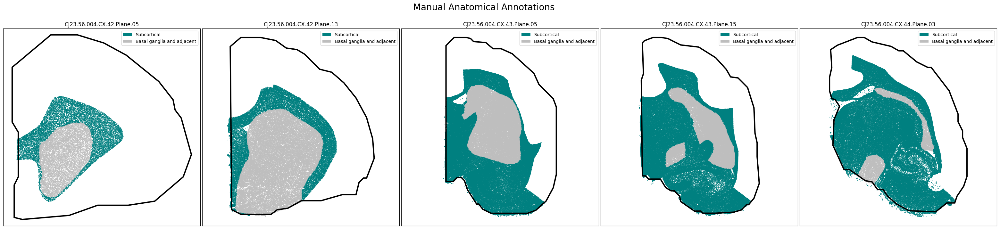

In [15]:
slab_list = [
    'CJ23.56.004.CX.42.Plane.05', 'CJ23.56.004.CX.42.Plane.13', 'CJ23.56.004.CX.43.Plane.05',
    'CJ23.56.004.CX.43.Plane.15', 'CJ23.56.004.CX.44.Plane.03'
]
feature = 'parcellation_term_symbol'
fig, ax = plot_slabs(
    cell_metadata,
    f'{feature}_color',
    slab_list,
    plot_polygons=True,
    labels=feature,
    term_orders=f'{feature}_order',
)
fig.suptitle(f'Manual Anatomical Annotations', size=20)
plt.show()

## Taxonomy mapping

Now that we have our base functions for plotting set up and we've exercised them using the parcellation colors, let's load the taxonomy information so that we can plot the spatial locations of various cell types. Below, we load and merge all the information we need to plot cell colors and taxonomy as done in the [previous HMBA-Subcortex tutorials](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_marmoset_clustering_analysis_and_annotation.html).

Below we load the mapping of the Marmoset Subcortex cells onto the HMBA-Subcortex-taxonomy-Marmoset at the cluster level.

In [16]:
cell_to_cluster_membership = abc_cache.get_metadata_dataframe(
    'HMBA-Subcortex-Xenium-Marmoset', 'cell_to_cluster_membership'
).set_index('cell_label')
cell_to_cluster_membership

cell_to_cluster_membership.csv: 100%|██████████| 355M/355M [00:28<00:00, 12.5MMB/s]   


,cluster_alias,label
cell_label,,
1382042951_aaondhbe-1-20250227,cluster_1092,CS20260831_LVL2_0977
1382042951_aaoneabm-1-20250227,cluster_902,CS20260831_LVL2_1370
1382042951_aaonekin-1-20250227,cluster_1092,CS20260831_LVL2_0977
1382042951_aaoofhco-1-20250227,cluster_1113,CS20260831_LVL2_0959
1382042951_aaopgffc-1-20250227,cluster_987,CS20260831_LVL2_1404
...,...,...
1388176147_oihjgghm-1-20250227,cluster_706,CS20260831_LVL2_1716
1388176147_oihjjhde-1-20250227,cluster_795,CS20260831_LVL2_1647
1388176147_oihjnnol-1-20250227,cluster_1283,CS20260831_LVL2_0732


Below we load the subcortex taxonomy. For more details on this taxonomy see the [notebook here](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_marmoset_clustering_analysis_and_annotation.html).

In [17]:
cluster = abc_cache.get_metadata_dataframe(
    'HMBA-Subcortex-taxonomy-Marmoset', 'cluster'
).set_index('label')
cluster_annotation_term = abc_cache.get_metadata_dataframe(
    'HMBA-Subcortex-taxonomy-Marmoset', 'cluster_annotation_term'
).set_index('label')

cluster_annotation_term_set = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-taxonomy-Marmoset',
    file_name='cluster_annotation_term_set'
).set_index('label')

cluster_to_cluster_annotation_membership = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-taxonomy-Marmoset',
    file_name='cluster_to_cluster_annotation_membership'
).set_index('cluster_annotation_term_label')

membership_with_cluster_info = cluster_to_cluster_annotation_membership.join(
    cluster.reset_index().set_index('cluster_alias')[['number_of_cells']],
    on='cluster_alias'
)

membership_with_cluster_info = membership_with_cluster_info.join(cluster_annotation_term, rsuffix='_anno_term').reset_index()

membership_groupby = membership_with_cluster_info.groupby(
    ['cluster_alias', 'cluster_annotation_term_set_name']
)

cluster_details = membership_groupby['cluster_annotation_term_name'].first().unstack()
cluster_order = membership_groupby['term_order'].first().unstack()

cluster_colors = membership_groupby['color_hex_triplet'].first().unstack()
cluster_colors = cluster_colors[cluster_annotation_term_set['name']]

cluster_to_dominant_region = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-taxonomy-Marmoset',
    file_name='cluster_to_dominant_region',
).set_index('cluster_alias')
cluster_to_neurotransmitter = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-taxonomy-Marmoset',
    file_name='cluster_to_neurotransmitter',
).set_index('cluster_alias')

Now we merge the cell type classification colors and order into our metadata.

In [18]:
cell_metadata = cell_metadata.join(cell_to_cluster_membership)
cell_metadata = cell_metadata.join(cluster_details, on='cluster_alias')
cell_metadata = cell_metadata.join(cluster_colors, on='cluster_alias', rsuffix='_color')
cell_metadata = cell_metadata.join(cluster_order, on='cluster_alias', rsuffix='_order')
cell_metadata = cell_metadata.join(cluster_to_dominant_region, on='cluster_alias', rsuffix='_region')
cell_metadata = cell_metadata.join(cluster_to_neurotransmitter, on='cluster_alias', rsuffix='_neurotransmitter')

del cell_to_cluster_membership

cell_metadata.head()

,brain_section_label,brain_section_barcode,x_experiment,y_experiment,segmentation_job_id,segmentation_method,cell_area,nucleus_area,n_nuclei_in_cell,total_counts,...,Class_color,Group_color,Cluster_color,Class_order,Cluster_order,Group_order,Cluster_dominant_region,Group_dominant_region,Cluster_neurotransmitter,Group_neurotransmitter
cell_label,,,,,,,,,,,,,,,,,,,,,
1382042951_aaondhbe-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4459.1006,4524.2420,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,89.81579,60.735157,1,339,...,#88CCEE,#BABA3B,#69efa5,11,978,125,Cx,Cx,Glut,Glut
1382042951_aaoneabm-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4668.6323,4653.2130,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,105.98172,74.327190,1,762,...,#CBC3E3,#708297,#bdb6cf,14,1371,166,Cx,STR,GABA,GABA
1382042951_aaonekin-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4593.0610,4594.6304,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,129.50813,74.598130,1,406,...,#88CCEE,#BABA3B,#69efa5,11,978,125,Cx,Cx,Glut,Glut
1382042951_aaoofhco-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4529.3900,4348.2266,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,136.37189,72.475784,1,948,...,#88CCEE,#BA723B,#cd5698,11,960,124,Cx,Cx,Glut,Glut
1382042951_aaopgffc-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4524.6533,4382.6323,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,129.41782,78.391250,1,941,...,#CBC3E3,#488edc,#1213f8,14,1405,168,Cx,STR,GABA,GABA


Merging in the taxonomy allows one to select cells by the specific taxons they are associated with, as we will see in a function we create below.

### Plotting the taxonomy

Now that the taxonomy is loaded, we plot the the cells showing the spatial locations of the cell types in the Subcortex. Below we plot each dataset for each of the 3 levels in the taxonomy selection using the same set of slabs we used in the previous section.

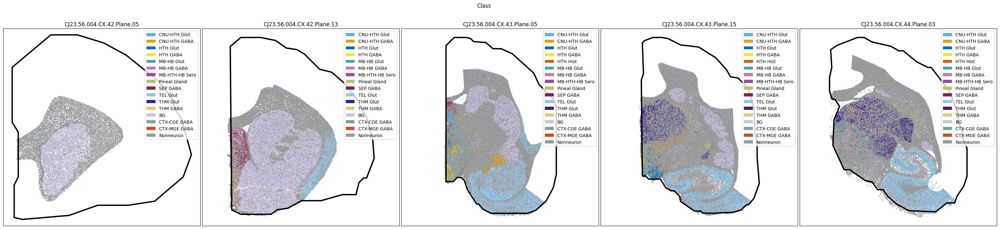

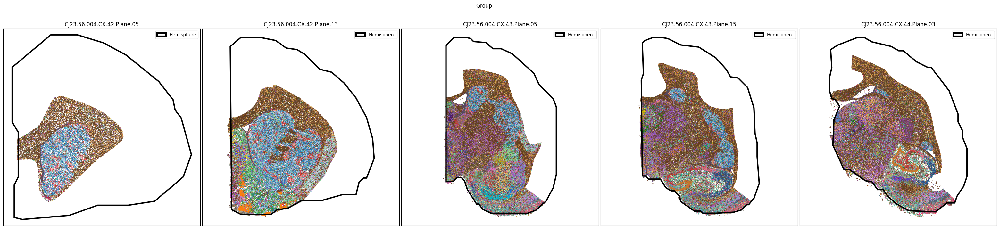

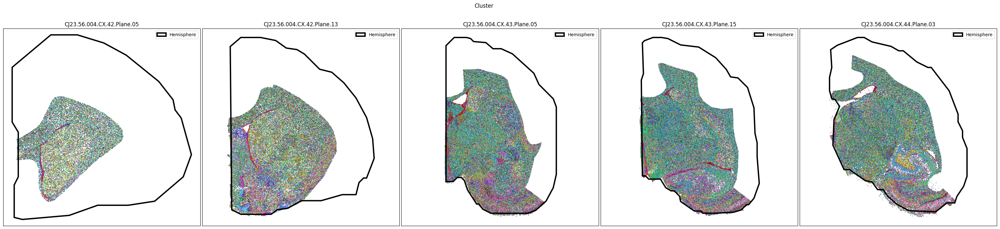

In [19]:
slab_list = [
    'CJ23.56.004.CX.42.Plane.05', 'CJ23.56.004.CX.42.Plane.13', 'CJ23.56.004.CX.43.Plane.05',
    'CJ23.56.004.CX.43.Plane.15', 'CJ23.56.004.CX.44.Plane.03'
]
for level in ['Class', 'Group', 'Cluster']:
    fig, ax = plot_slabs(
        cell_metadata,
        f'{level}_color',
        slab_list,
        plot_polygons=True,
        labels=level if level == 'Class' else None,
        term_orders=f'{level}_order' if level == 'Class' else None
    )
    fig.suptitle(f'{level}')
    plt.show()

### Selecting cell types

We define a slightly modified version of our slab plotting function that allows us to plot specific cell types, coloring by cell type level that is nominally lower in the taxonomy. This allows for us to investigate the spatial distribution of cell types more clearly by, for instance, plotting the spatial distributions of Groups localized to the Amygdala. 
 
In general, cells associated with individual cell types and taxons can be selected by masking the DataFrame using the desired column and value in that column, as we showed in our examples above. For instance to select the Class, TEL Glut, we can create a mask thusly `cell_metadata['Class']=='TEL Glut'` and similarly for the other species. Again, this function can be used to plot individual slab planes and selections as well.

In [20]:
def plot_selected_cells(
    df: pd.DataFrame,
    feature: str,
    selection_list: List[Tuple[str, str]],
    slab: str,
    cmap: Optional[plt.Colormap] = None,
    fig_width: float = 40,
    fig_height: float = 8,
    plot_polygons: bool = True,
    point_size: float = 1.0,
    fix_bounds: bool = False,
    labels: str = None,
    term_orders: str = None,
):
    """Plot spatial transcriptomics data selected a cell type and colored by
    a feature of interest.

    Parameters
    ----------
    df: pandas.DataFrame
        cell metadata data frame with x,y locations to plot.
    feature: str
        Expression value or color column to plot.
    selection_list: List[str]
        Set of cell types to select by. Specify as ('taxonomy_level_name', 'cell type')
    slab: str
        Specific slab to plot.
    cmap: matplotlib.colors.Colormap
        Colormap for expression features.
    fid_width: int
        Width of the plotted figure.
    fig_height: iont
        Height of the plotted figure.
    plot_polygons: bool
        Overplot geojson polygons. Note that these are note available for human
        and this should be set to False.
    point_size: float
        Size of the points to plot.
    fix_bounds: bool
        If True, fix the x and y bounds across all slabs to be the same.
    labels : array-like, optional
        labels for the points to plot. If None, no labels will be added to the plot.
    term_orders : array-like, optional
        order of the labels for the legend. If None, the labels will be ordered by their appearance in `labels`.  
    """
    
    fig, ax = plt.subplots(1, len(selection_list))
    fig.set_size_inches(fig_width, fig_height)

    if len(selection_list) == 1:
        ax = [ax]

    if 'slab_plane_label' in df.columns:
        slab_filtered = df[df['slab_plane_label']==slab]
    elif 'brain_section_label' in df.columns:
        slab_filtered = df[df['brain_section_label']==slab]

    if 'x' in df.columns:
        x_col = 'x'
    elif 'x_rotated_mm' in df.columns:
        x_col = 'x_rotated_mm'
    if 'y' in df.columns:
        y_col = 'y'
    elif 'y_rotated_mm' in df.columns:
        y_col = 'y_rotated_mm'

    if fix_bounds:
        x_min = slab_filtered[x_col].min()
        x_max = slab_filtered[x_col].max()
        y_min = slab_filtered[y_col].min()
        y_max = slab_filtered[y_col].max()
    
    for idx, (col, name) in enumerate(selection_list):

        if 'slab_plane_label' in df.columns:
            filtered = slab_filtered[slab_filtered[col]==name]
        elif 'brain_section_label' in df.columns:
            filtered = slab_filtered[slab_filtered[col]==name]
        xx = filtered[x_col]
        yy = filtered[y_col]
        vv = filtered[feature]
        if labels is not None:
            ll = filtered[labels]
        if term_orders is not None:
            oo = filtered[term_orders]

        
        if cmap is not None:
            ax[idx].scatter(xx, yy, s=point_size, c=vv, marker='.', cmap=cmap)
        else :
            ax[idx].scatter(xx, yy, s=point_size, c=vv, marker=".")

        if plot_polygons:
            plot_geo_data(get_polygons(slab), ax[idx])
            
        ax[idx].axis('equal')
        ylim = ax[idx].get_ylim()
        if fix_bounds:
            ylim = (y_min, y_max)
            ax[idx].set_xlim(x_min, x_max)
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])
        
        ax[idx].set_title(name)
        if labels is not None:
            from matplotlib.patches import Rectangle
            unique_label_colors = (ll + ',' + vv).unique()
            unique_labels = np.array([label_color.split(',')[0] for label_color in unique_label_colors])
            unique_colors = np.array([label_color.split(',')[1] for label_color in unique_label_colors])
    
            if term_orders is not None:
                unique_order = oo.unique()
                term_order = np.argsort(unique_order)
                unique_labels = unique_labels[term_order]
                unique_colors = unique_colors[term_order]
                
            rects = []
            for color in unique_colors:
                rects.append(Rectangle((0, 0), 1, 1, fc=color))
    
            legend = ax[idx].legend(rects, unique_labels, loc=1)
            # ax.add_artist(legend)
        else:
            ax[idx].legend(loc=0)
        
    plt.subplots_adjust(wspace=0.01, hspace=0.01)
    fig.suptitle(f'{slab}')
    return fig, ax

Using the above function, we plot the cells colored by their Group color and selected by specific Classes and Groups.

CJ23.56.004.CX.42.Plane.22.geojson: 100%|██████████| 1.39k/1.39k [00:00<00:00, 27.0kMB/s]


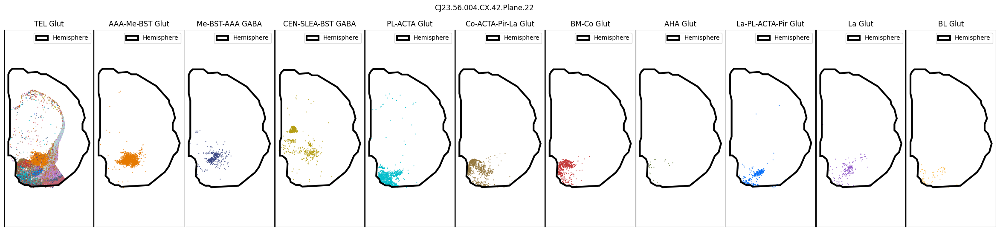

CJ23.56.004.CX.43.Plane.04.geojson: 100%|██████████| 1.58k/1.58k [00:00<00:00, 17.7kMB/s]


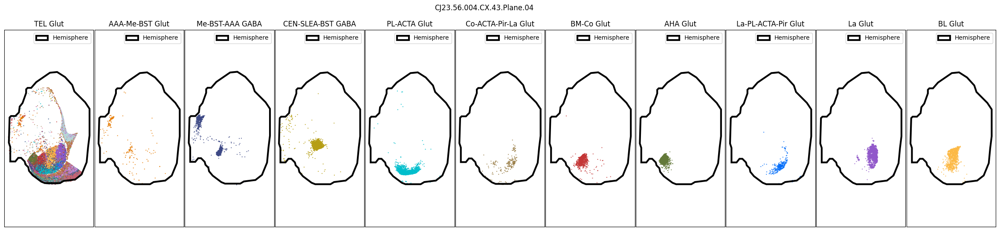

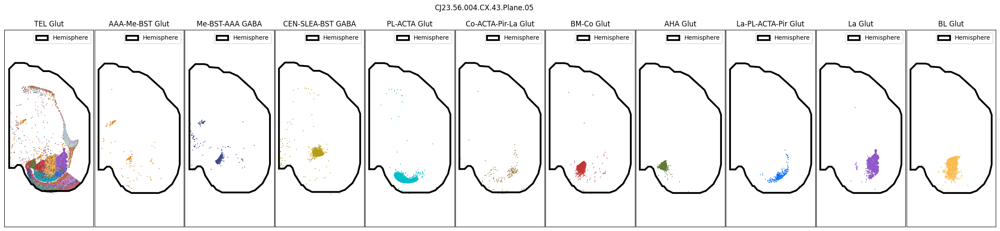

CJ23.56.004.CX.43.Plane.06.geojson: 100%|██████████| 1.43k/1.43k [00:00<00:00, 31.9kMB/s]


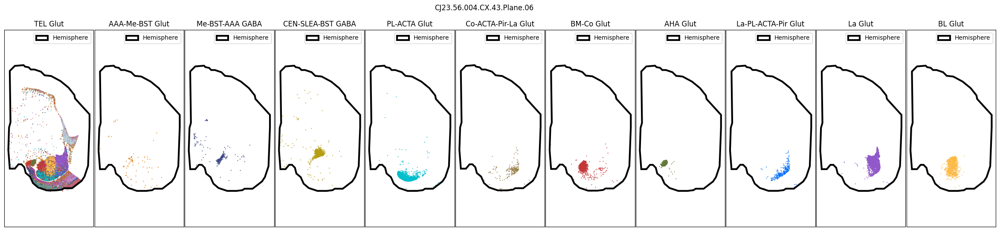

CJ23.56.004.CX.43.Plane.08.geojson: 100%|██████████| 1.41k/1.41k [00:00<00:00, 22.8kMB/s]


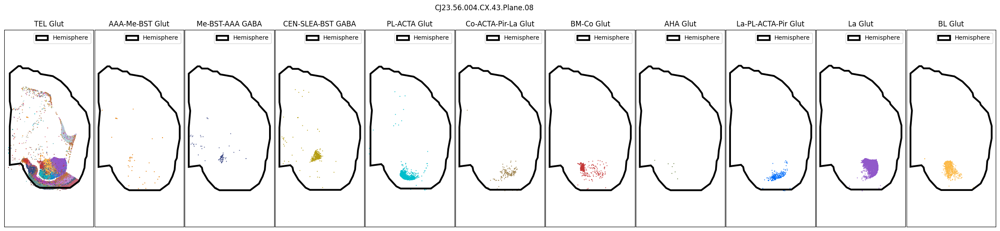

CJ23.56.004.CX.43.Plane.10.geojson: 100%|██████████| 1.06k/1.06k [00:00<00:00, 21.8kMB/s]


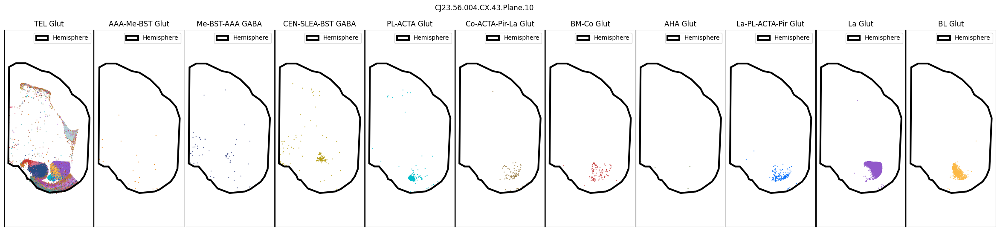

CJ23.56.004.CX.43.Plane.11.geojson: 100%|██████████| 1.08k/1.08k [00:00<00:00, 19.6kMB/s]


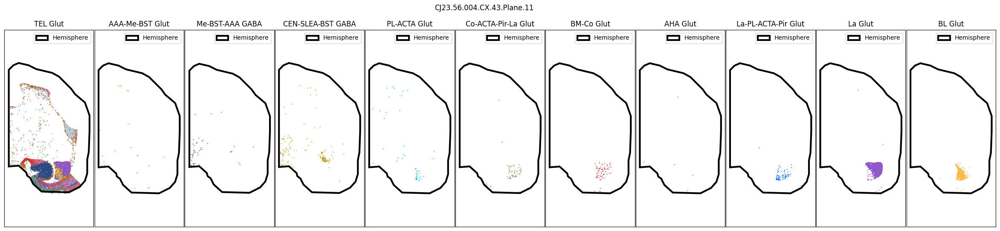

In [21]:
slab_list = [
    'CJ23.56.004.CX.42.Plane.22',
    'CJ23.56.004.CX.43.Plane.04', 
    'CJ23.56.004.CX.43.Plane.05',
    'CJ23.56.004.CX.43.Plane.06',
    'CJ23.56.004.CX.43.Plane.08',
    'CJ23.56.004.CX.43.Plane.10',
    'CJ23.56.004.CX.43.Plane.11',
]

for slab in slab_list:
    fig, ax = plot_selected_cells(
        cell_metadata,
        feature='Group_color',
        selection_list=[
            ('Class', 'TEL Glut'),
            ('Group', 'AAA-Me-BST Glut'),
            ('Group', 'Me-BST-AAA GABA'),
            ('Group', 'CEN-SLEA-BST GABA'),
            ('Group', 'PL-ACTA Glut'),
            ('Group', 'Co-ACTA-Pir-La Glut'),
            ('Group', 'BM-Co Glut'),
            ('Group', 'AHA Glut'),
            ('Group', 'La-PL-ACTA-Pir Glut'),
            ('Group', 'La Glut'),
            ('Group', 'BL Glut'),
        ],
        slab=slab,
        fig_width=30,
        fig_height=6,
        plot_polygons=True,
    )
    plt.show()

We can also plot the cells colored by their Cluster level.

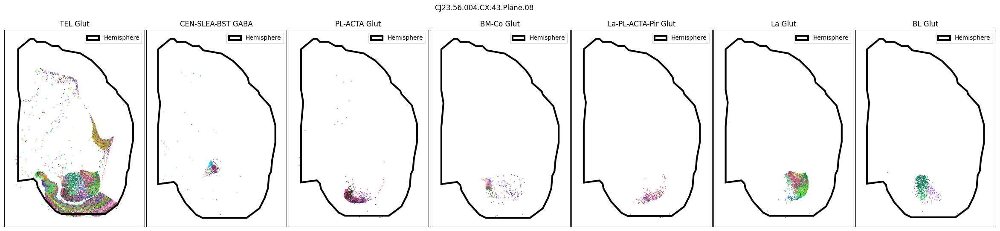

In [22]:
slab_list = [
    'CJ23.56.004.CX.43.Plane.08',
]

for slab in slab_list:
    fig, ax = plot_selected_cells(
        cell_metadata,
        feature='Cluster_color',
        selection_list=[
            ('Class', 'TEL Glut'),
            # ('Group', 'AAA-Me-BST Glut'),
            # ('Group', 'Me-BST-AAA GABA'),
            ('Group', 'CEN-SLEA-BST GABA'),
            ('Group', 'PL-ACTA Glut'),
            # ('Group', 'Co-ACTA-Pir-La Glut'),
            ('Group', 'BM-Co Glut'),
            # ('Group', 'AHA Glut'),
            ('Group', 'La-PL-ACTA-Pir Glut'),
            ('Group', 'La Glut'),
            ('Group', 'BL Glut'),
        ],
        slab=slab,
        fig_width=30,
        fig_height=6,
        plot_polygons=True,
    )
    plt.show()

### Region and Neurotransmitter

As with the tutorial for the Subcortex taxonomy, we have information for the dominant brain region and neurotransmitter type, derived from the cell type taxonomy, at both the Cluster and Group level.

e load both the Group and Cluster’s dominant region and neurotransmitter colors and orders below.”

In [23]:
extract_value_set(cell_metadata, value_sets, 'Cluster_neurotransmitter', 'neurotransmitter')
extract_value_set(cell_metadata, value_sets, 'Group_neurotransmitter', 'neurotransmitter')
extract_value_set(cell_metadata, value_sets, 'Cluster_dominant_region', 'dominant_region')
extract_value_set(cell_metadata, value_sets, 'Group_dominant_region', 'dominant_region')

Finally, we plot the dominant region and neurotransmitter for the subcortex data.

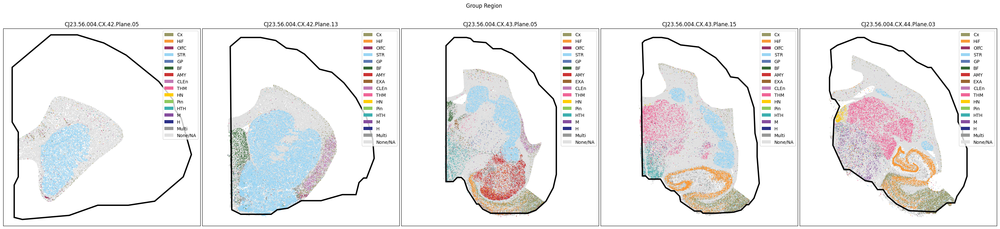

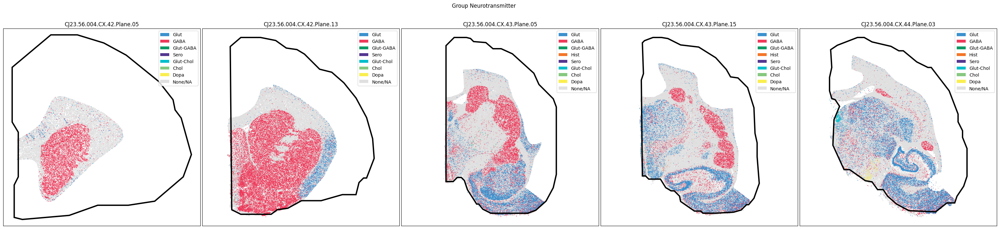

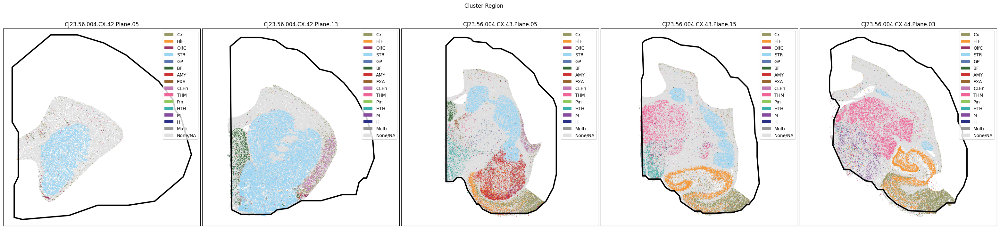

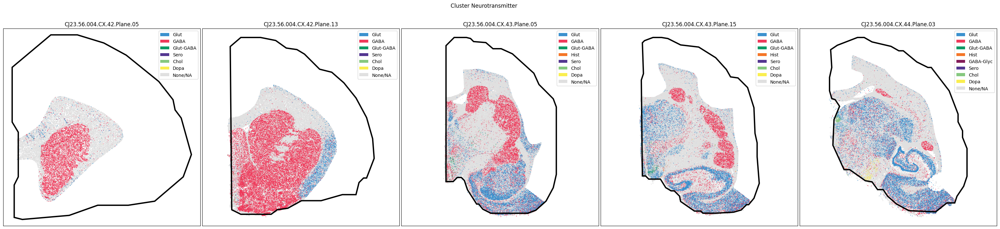

In [24]:
slab_list = [
    'CJ23.56.004.CX.42.Plane.05', 'CJ23.56.004.CX.42.Plane.13', 'CJ23.56.004.CX.43.Plane.05',
    'CJ23.56.004.CX.43.Plane.15', 'CJ23.56.004.CX.44.Plane.03'
]
for celltype in ['Group', 'Cluster']:
    fig, ax = plot_slabs(
        cell_metadata,
        f'{celltype}_dominant_region_color',
        slab_list,
        plot_polygons=True,
        labels=f'{celltype}_dominant_region',
        term_orders=f'{celltype}_dominant_region_order'
    )
    fig.suptitle(f'{celltype} Region')
    plt.show()
    fig, ax = plot_slabs(
        cell_metadata,
        f'{celltype}_neurotransmitter_color',
        slab_list,
        plot_polygons=True,
        labels=f'{celltype}_neurotransmitter',
        term_orders=f'{celltype}_neurotransmitter_order'
    )
    fig.suptitle(f'{celltype} Neurotransmitter')
    plt.show()

In the next tutorial, we will explore [gene expression patterns across these spatial transcriptomics datasets](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_marmoset_spatial_genes.html).

To learn more about the taxonomy used in this notebook and the data it is derived from, see the [HMBA-Subcortex Clustering Analysis and Taxonomy notebook](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_clustering_analysis_and_annotation.html).